# Soluzioni — Lezione 9: Dimostrare e discutere
[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yuri-bizzoni/yuribizzoni/blob/main/ml-humanities/solutions/09_dimostrare_e_discutere_soluzioni.ipynb)

In [1]:
# ⚙️ CELLA DI PREPARAZIONE — eseguitela per prima (Shift+Invio) e non preoccupatevi del codice.
# Cerca la cartella "data" del corso; se non la trova (per esempio su Google Colab),
# scarica il materiale del corso da GitHub. Funziona anche senza internet, se avete la cartella.
from pathlib import Path
import subprocess

def trova_dati():
    for p in [Path("../data"), Path("data"), Path("ml-humanities/data"), Path("yuribizzoni/ml-humanities/data")]:
        if (p / "lessico_felicita.csv").exists():
            return p
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/yuri-bizzoni/yuribizzoni"], check=True)
    return Path("yuribizzoni/ml-humanities/data")

DATI = trova_dati()
print("Dati trovati in:", DATI.resolve())

Dati trovati in: /home/user/yuribizzoni/ml-humanities/data


In [2]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

def leggi_testo(nome):
    righe = (DATI / "testi" / nome).read_text(encoding="utf-8").splitlines()
    return "\n".join(r for r in righe if not r.startswith("#"))

def brani(testo, n_parole=200):
    """Divide un testo in brani di almeno n_parole, senza spezzare i paragrafi."""
    paragrafi = [" ".join(p.split()) for p in re.split(r"\n\s*\n", testo) if len(p.split()) > 3]
    out, cur = [], []
    for p in paragrafi:
        cur.append(p)
        if sum(len(x.split()) for x in cur) >= n_parole:
            out.append(" ".join(cur)); cur = []
    return out

passaggi = pd.read_csv(DATI / "passaggi_autori.csv")

## Esercizio 1 — Trova il trucco

In [3]:
print(passaggi["id_passaggio"].head(3).tolist())

['collodi_pinocchio_001', 'collodi_pinocchio_004', 'collodi_pinocchio_006']


L'"identificativo per sicurezza" contiene il **nome del file** dell'opera (`collodi_pinocchio_012`, `manzoni_promessi_sposi_034`…):
la risposta è scritta nell'input. Il vettorizzatore trasforma *collodi*, *manzoni*, *pirandello* in parole, e la SVM impara a leggerle.
È un caso da manuale di **data leakage**. Correzione: usare solo il testo.

In [4]:
dati = passaggi.copy()
dati["inizio"] = dati["testo"].str.split().str[:5].str.join(" ")
Xa, Xb, ya, yb = train_test_split(dati["inizio"], dati["autore"], test_size=0.25, random_state=0, stratify=dati["autore"])
corretto = make_pipeline(TfidfVectorizer(), LinearSVC()).fit(Xa, ya)
print(f"Accuratezza vera con 5 parole: {corretto.score(Xb, yb):.0%}  (baseline: 20%)")

Accuratezza vera con 5 parole: 42%  (baseline: 20%)


**Commento.** Con 5 parole il compito è difficile: l'accuratezza vera è molto più bassa del 100%, anche se ancora sopra la baseline.
Regola pratica: quando un risultato è troppo bello, cercate la colonna (o il dettaglio di preparazione) che contiene la risposta.

## Esercizio 2 — Un grafico per la presentazione

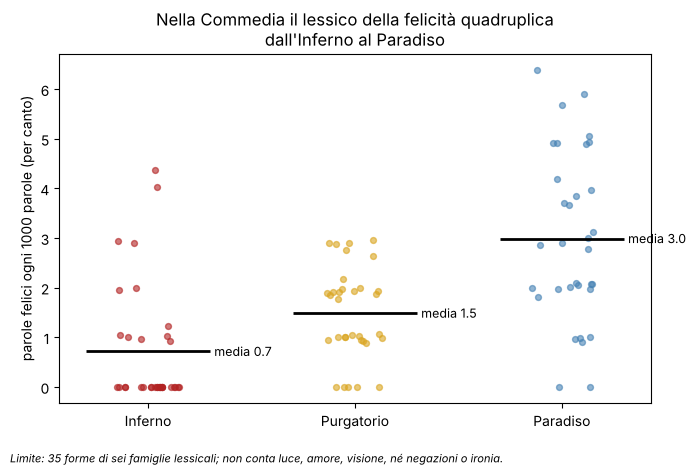

In [5]:
famiglie = pd.read_csv(DATI / "famiglie_felicita_it.csv")
FORME_FELICI = set(famiglie["forma"])
dc = pd.read_csv(DATI / "commedia_canti.csv")
dc["felici_1000"] = dc["testo"].apply(lambda t: (lambda w: sum(x in FORME_FELICI for x in w) / len(w) * 1000)(re.findall(r"\w+", t.lower())))

cantiche = ["Inferno", "Purgatorio", "Paradiso"]
colori = {"Inferno": "firebrick", "Purgatorio": "goldenrod", "Paradiso": "steelblue"}
fig, ax = plt.subplots(figsize=(7, 4.5))
rng = np.random.default_rng(0)
for i, c in enumerate(cantiche):
    valori = dc.loc[dc["cantica"] == c, "felici_1000"]
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(valori)), valori, color=colori[c], alpha=0.6, s=18)   # ogni punto = un canto
    ax.hlines(valori.mean(), i - 0.3, i + 0.3, color="black", lw=2)
    ax.text(i + 0.32, valori.mean(), f"media {valori.mean():.1f}", va="center", fontsize=9)
ax.set_xticks(range(3), cantiche)
ax.set_ylabel("parole felici ogni 1000 parole (per canto)")
ax.set_title("Nella Commedia il lessico della felicità quadruplica\ndall'Inferno al Paradiso")
fig.text(0.01, -0.04, "Limite: 35 forme di sei famiglie lessicali; non conta luce, amore, visione, né negazioni o ironia.",
         fontsize=8, style="italic")
plt.tight_layout(); plt.show()

**Commento.** Il titolo **dice il risultato**, i punti mostrano la **variabilità** tra canti (non solo la media), la nota dichiara il
**limite** principale. Un buon grafico da presentazione si capisce in dieci secondi e non promette più di quanto i dati sostengano.

## Esercizio 3 — Il quiz

In [6]:
DOMANDE = {
    1: ("Un classificatore ha il 97% di accuratezza su un compito in cui il 97% degli esempi è negativo. È buono?",
        {"a": "Sì, 97% è altissimo", "b": "Non si può dire: bisogna confrontarlo con la baseline e guardare precision e recall",
         "c": "No, sotto il 99% è sempre scadente"}),
    2: ("Che cosa misura la recall?",
        {"a": "Di ciò che ho trovato, quanto è giusto", "b": "Di ciò che c'era da trovare, quanto ho trovato",
         "c": "La percentuale totale di risposte giuste"}),
    3: ("Per la semantica distribuzionale 'gioia' e 'dolore' risultano simili. Perché?",
        {"a": "Perché il modello è sbagliato", "b": "Perché hanno lo stesso significato",
         "c": "Perché compaiono in contesti simili (es. 'provò una grande ___')"}),
    4: ("Il k-means ha bisogno di etichette (risposte giuste) per funzionare?",
        {"a": "Sì, come la SVM", "b": "No, è un metodo non supervisionato; ma il numero di gruppi k lo scegliamo noi",
         "c": "No, e sceglie da solo il numero giusto di gruppi"}),
    5: ("Un modello di lingua a 4-grammi genera un verso di Dante perfetto. Che cosa è più probabile?",
        {"a": "Ha capito lo stile di Dante", "b": "Ha ricopiato un pezzo del corpus di addestramento",
         "c": "Ha inventato un verso nuovo per caso"}),
    6: ("Un classificatore d'autore addestrato su un solo libro per autore funziona al 100%. Qual è il dubbio principale?",
        {"a": "Che riconosca il libro (personaggi, genere, edizione) più che l'autore",
         "b": "Che il computer fosse troppo lento", "c": "Nessun dubbio: 100% è la prova che funziona"}),
}

def quiz(risposte):
    """risposte: un dizionario {numero_domanda: "lettera"}"""
    giuste = {1: "b", 2: "b", 3: "c", 4: "b", 5: "b", 6: "a"}
    punti = 0
    for n, (domanda, _) in DOMANDE.items():
        r = risposte.get(n, "")
        ok = r == giuste[n]
        punti += ok
        print(f"{'✅' if ok else '❌'} {n}. {domanda[:70]}…  (vostra risposta: {r or '—'})")
    print(f"\nPunteggio: {punti}/{len(DOMANDE)}")

for n, (domanda, opzioni) in DOMANDE.items():
    print(f"{n}. {domanda}")
    for lettera, testo in opzioni.items():
        print(f"     {lettera}) {testo}")

1. Un classificatore ha il 97% di accuratezza su un compito in cui il 97% degli esempi è negativo. È buono?
     a) Sì, 97% è altissimo
     b) Non si può dire: bisogna confrontarlo con la baseline e guardare precision e recall
     c) No, sotto il 99% è sempre scadente
2. Che cosa misura la recall?
     a) Di ciò che ho trovato, quanto è giusto
     b) Di ciò che c'era da trovare, quanto ho trovato
     c) La percentuale totale di risposte giuste
3. Per la semantica distribuzionale 'gioia' e 'dolore' risultano simili. Perché?
     a) Perché il modello è sbagliato
     b) Perché hanno lo stesso significato
     c) Perché compaiono in contesti simili (es. 'provò una grande ___')
4. Il k-means ha bisogno di etichette (risposte giuste) per funzionare?
     a) Sì, come la SVM
     b) No, è un metodo non supervisionato; ma il numero di gruppi k lo scegliamo noi
     c) No, e sceglie da solo il numero giusto di gruppi
5. Un modello di lingua a 4-grammi genera un verso di Dante perfetto. Che 

In [7]:
quiz({1: "b", 2: "b", 3: "c", 4: "b", 5: "b", 6: "a"})

✅ 1. Un classificatore ha il 97% di accuratezza su un compito in cui il 97%…  (vostra risposta: b)
✅ 2. Che cosa misura la recall?…  (vostra risposta: b)
✅ 3. Per la semantica distribuzionale 'gioia' e 'dolore' risultano simili. …  (vostra risposta: c)
✅ 4. Il k-means ha bisogno di etichette (risposte giuste) per funzionare?…  (vostra risposta: b)
✅ 5. Un modello di lingua a 4-grammi genera un verso di Dante perfetto. Che…  (vostra risposta: b)
✅ 6. Un classificatore d'autore addestrato su un solo libro per autore funz…  (vostra risposta: a)

Punteggio: 6/6


**Spiegazioni.**
1. **b** — con il 97% di negativi, "sempre no" fa già 97% (lezione 4).
2. **b** — la recall misura quanto ho trovato di ciò che c'era; la precision quanto è giusto ciò che ho trovato.
3. **c** — gli opposti condividono i contesti; la semantica distribuzionale misura la sostituibilità, non il "significato uguale" (lezione 7).
4. **b** — non supervisionato, ma *k* è una scelta nostra; la silhouette aiuta, non decide (lezione 5).
5. **b** — con contesti lunghi e pochi dati il modello ricopia (lezione 8).
6. **a** — autore, opera e genere sono confusi nei dati; lo mostra l'esperimento sull'*Umorismo* (questa lezione).